# Alerta temprana de pérdida de materias

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LegalmentePablo/prediccion-rendimiento-academico/blob/main/notebooks/analisis.ipynb)

¿Se puede anticipar, al cerrar el **periodo 1**, qué estudiantes van a perder una materia en el
**periodo 2**? Este notebook recorre el análisis completo: revisa la calidad de los datos y
compara cinco modelos y dos líneas base, evaluados sin fugas de información.

Toda la lógica vive en el paquete `prediccion_rendimiento` (carpeta `src/`); aquí solo se usa.

In [1]:
# En Google Colab descarga el proyecto e instala el paquete; en local no hace nada.
import sys

if "google.colab" in sys.modules:
    !git clone -q https://github.com/LegalmentePablo/prediccion-rendimiento-academico.git
    %cd prediccion-rendimiento-academico
    %pip install -q .

In [2]:
from pathlib import Path

import pandas as pd

from prediccion_rendimiento import analizar, cargar_datos, graficos, reporte_calidad

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
pd.options.display.precision = 3

df = cargar_datos(RAIZ / "data" / "raw")
df.head()

,estudiante,nota_p1,nota_p2,pierde_p1_reportado,pierde_p2_reportado,materia,pierde_p1,pierde_p2
0,1,4.2,3.5,0,0,Matemáticas,0,0
1,2,4.2,3.7,0,0,Matemáticas,0,0
2,3,4.2,3.0,0,0,Matemáticas,0,0
3,4,4.3,3.7,0,0,Matemáticas,0,0
4,5,3.9,3.1,0,0,Matemáticas,0,0


## 1. Calidad de los datos

Cada archivo trae, por estudiante, la nota de dos periodos (escala 0–5) y si «pierde» cada uno.
La regla esperada es *pierde si la nota es menor a 3,0*. La tabla mide cuánto se cumple.

In [3]:
calidad = reporte_calidad(df)
calidad

,estudiantes,pierde_p1,pierde_p2,etiqueta_p1_coherente,etiqueta_p2_coherente,correlacion_p1_p2
materia,,,,,,
Matemáticas,2718,0.213,0.174,0.993,0.998,0.400
Inglés,2717,0.331,0.305,1.000,0.978,0.137
Física,2717,0.331,0.304,1.000,0.988,0.156
Ciencias sociales,2717,0.331,0.361,1.000,1.000,0.062
Ciencias naturales,2718,0.475,0.467,0.512,0.504,0.044


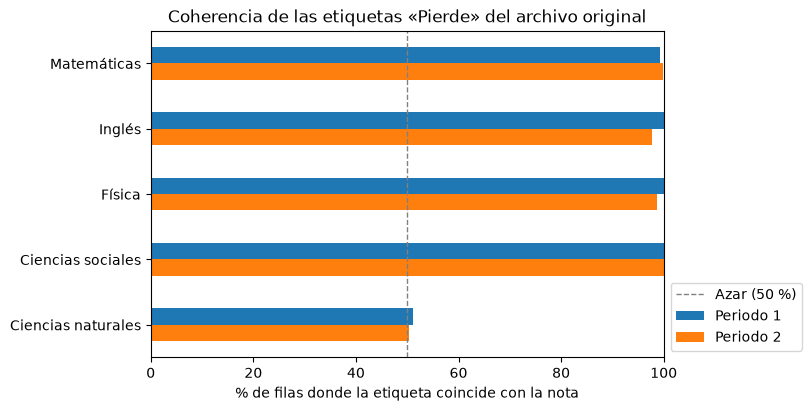

In [4]:
graficos.coherencia_etiquetas(calidad);

- En **Ciencias naturales** las etiquetas coinciden con la nota solo ~50 % de las veces: son
  aleatorias. Por eso el proyecto **recalcula la etiqueta a partir de la nota** (`nota < 3`) y
  guarda la original como `pierde_*_reportado`.
- La nota del periodo 1 es idéntica en Inglés, Física y Ciencias sociales para cada estudiante, así
  que un mismo estudiante aporta filas casi duplicadas. La división entrenamiento/prueba se hace
  **por estudiante** para que esas copias no se filtren a la prueba.

## 2. Planteamiento

- **Pregunta:** con lo que se sabe al cerrar el periodo 1 (nota y materia), ¿perderá el periodo 2?
- **Sin fugas:** ningún rasgo usa información del periodo 2.
- **Balanceo correcto:** SMOTENC va dentro del pipeline, así que solo toca los datos de
  entrenamiento de cada pliegue.
- **Dos líneas base:** la regla «si perdió el periodo 1, pierde el periodo 2» y la tasa de pérdida
  de cada materia (ignora la nota). Un modelo solo vale la pena si supera a ambas.

La señal disponible es limitada. Así se ve el riesgo real según la nota del periodo 1:

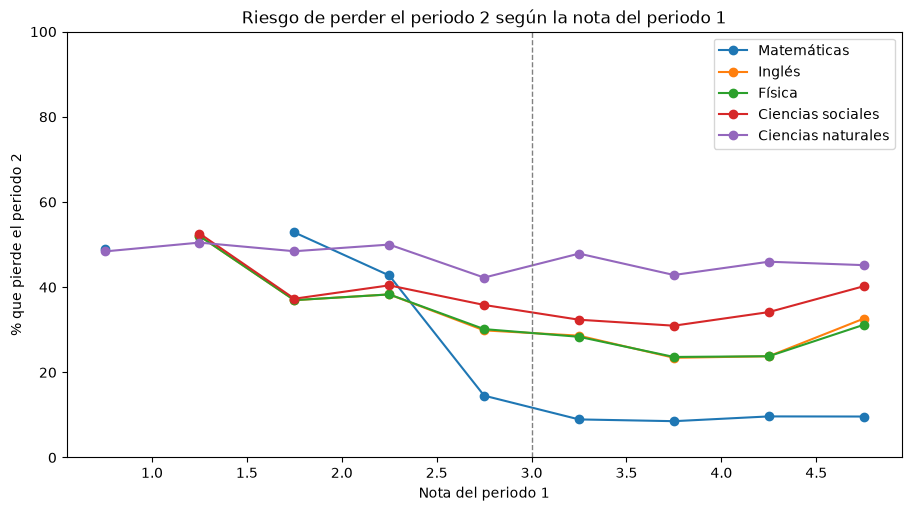

In [5]:
graficos.riesgo_por_nota(df);

Matemáticas muestra una relación clara entre ambos periodos. En Inglés y Física la nota del
periodo 1 cambia poco el riesgo, y en Ciencias sociales y Ciencias naturales casi nada.

## 3. Comparación de modelos (validación cruzada, 5 pliegues por estudiante)

`analizar` aparta el 20 % de los estudiantes para la prueba final, compara los modelos con
validación cruzada en el resto y elige el mejor por AUC sin mirar la prueba.

In [6]:
r = analizar(df)
r.validacion_cruzada.filter(like="media")

,AUC ROC media,Exactitud balanceada media,Sensibilidad media,Precisión media,F1 media
Árbol de decisión,0.666,0.625,0.739,0.419,0.535
Red neuronal (MLP),0.663,0.617,0.618,0.436,0.509
Bosque aleatorio,0.657,0.602,0.657,0.409,0.504
KNN,0.650,0.558,0.251,0.471,0.327
Regresión logística,0.647,0.608,0.603,0.426,0.499
Tasa por materia,0.619,0.585,0.515,0.415,0.460
Regla: nota P1 < 3,0.595,0.593,0.464,0.443,0.453


## 4. Evaluación final en el conjunto de prueba (20 %, nunca visto)

In [7]:
r.prueba

,AUC ROC,Exactitud balanceada,Sensibilidad,Precisión,F1
Bosque aleatorio,0.654,0.614,0.660,0.421,0.514
Red neuronal (MLP),0.651,0.613,0.702,0.412,0.519
Árbol de decisión,0.644,0.613,0.726,0.408,0.523
KNN,0.635,0.556,0.269,0.448,0.336
Regresión logística,0.625,0.594,0.579,0.414,0.482
Tasa por materia,0.613,0.580,0.509,0.410,0.454
Regla: nota P1 < 3,0.561,0.568,0.422,0.412,0.417


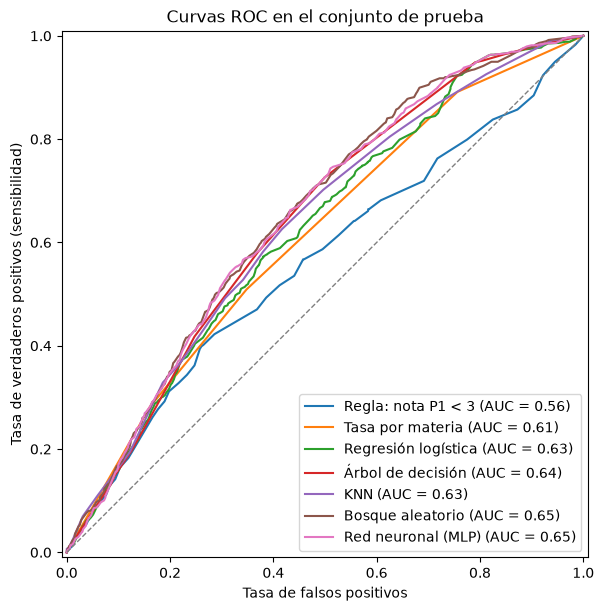

In [8]:
graficos.curvas_roc(r.ajustados, r.particion);

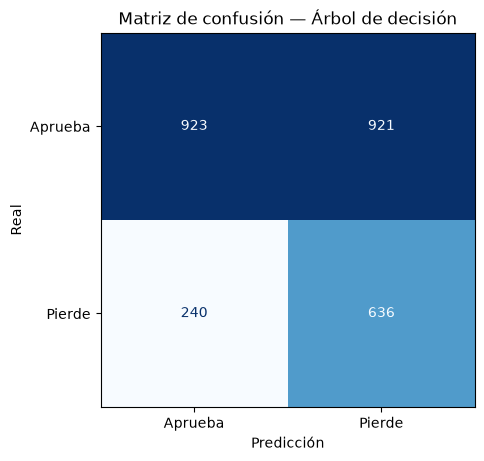

In [9]:
graficos.matriz_confusion(r.ajustados[r.mejor], r.particion, r.mejor);

## 5. Conclusiones

- El árbol de decisión, la red neuronal y el bosque aleatorio detectan entre el 66 % y el 73 % de
  quienes perderán el periodo 2; la regla simple detecta el 42 %.
- No es solo cuestión de mover el umbral: si la regla se relaja a `nota < 4` llega a una
  sensibilidad parecida (68 %), pero su precisión cae a 0,35. Los modelos mantienen ~0,41.
- Buena parte de la ventaja viene de saber la materia: la tasa por materia sola ya logra un AUC de
  0,613. La nota del periodo 1 añade unos 0,04 más (0,644–0,654).
- De cada 5 alertas, unas 2 aciertan. Para una **alerta temprana** (tutorías, seguimiento) es
  útil; para decisiones con consecuencias, no.
- Los modelos complejos apenas superan a un árbol de decisión de profundidad 4: con dos variables
  no hay más patrón que aprender.

**Limitaciones:** los datos tienen señales de ser sintéticos o de haberse armado copiando columnas
(etiquetas aleatorias en Ciencias naturales, notas del periodo 1 idénticas entre materias). Con
datos reales y más variables (asistencia, historial, otras materias) el resultado podría ser muy
distinto.